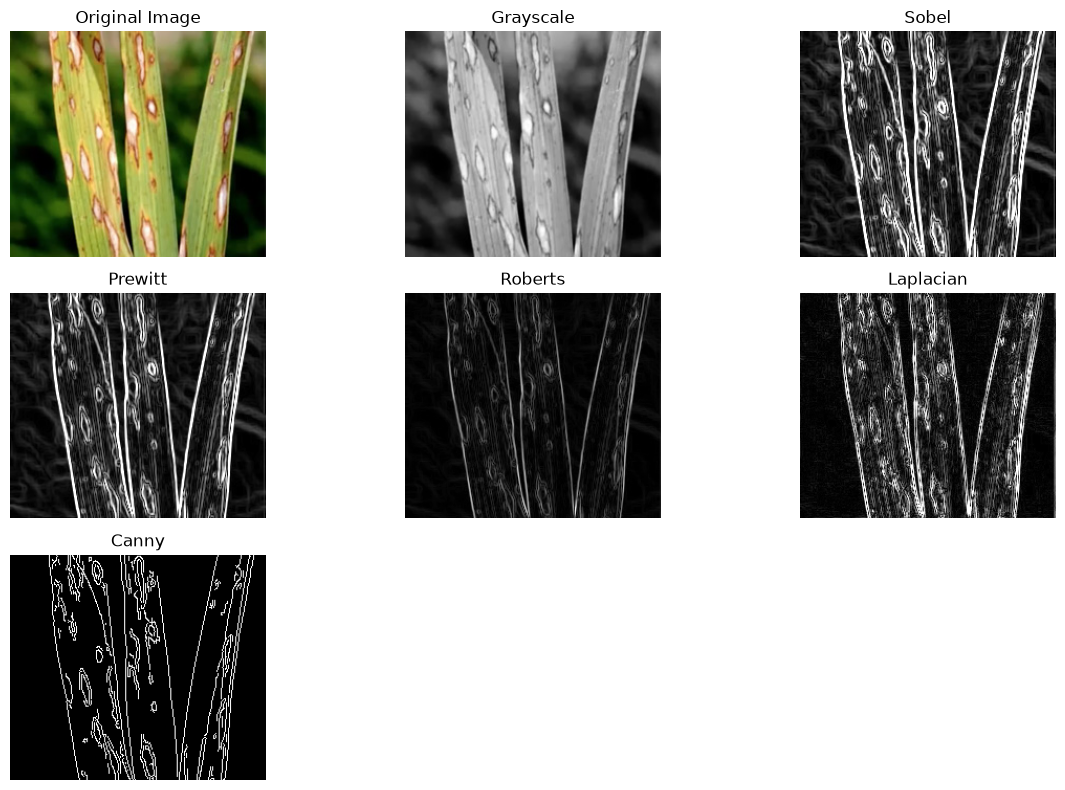

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load image
img = cv2.imread("C:/Users/vikam/OneDrive/Desktop/pic1.jpg")

if img is None:
    raise FileNotFoundError("Image not found. Check the image path.")

# Convert to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# 1. Sobel Edge Detection
sobel_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
sobel = cv2.magnitude(sobel_x, sobel_y)
sobel = cv2.convertScaleAbs(sobel)

# 2. Prewitt Edge Detection
prewitt_x = np.array([[-1, 0, 1],
                      [-1, 0, 1],
                      [-1, 0, 1]], dtype=np.float32)

prewitt_y = np.array([[-1, -1, -1],
                      [ 0,  0,  0],
                      [ 1,  1,  1]], dtype=np.float32)

px = cv2.filter2D(gray, cv2.CV_32F, prewitt_x)
py = cv2.filter2D(gray, cv2.CV_32F, prewitt_y)
prewitt = cv2.magnitude(px, py)
prewitt = cv2.convertScaleAbs(prewitt)

# 3. Roberts Edge Detection
roberts_x = np.array([[1, 0],
                      [0, -1]], dtype=np.float32)

roberts_y = np.array([[0, 1],
                      [-1, 0]], dtype=np.float32)

rx = cv2.filter2D(gray, cv2.CV_32F, roberts_x)
ry = cv2.filter2D(gray, cv2.CV_32F, roberts_y)
roberts = cv2.magnitude(rx, ry)
roberts = cv2.convertScaleAbs(roberts)

# 4. Laplacian Edge Detection
laplacian = cv2.Laplacian(gray, cv2.CV_64F, ksize=3)
laplacian = cv2.convertScaleAbs(laplacian)

# 5. Canny Edge Detection
canny = cv2.Canny(gray, 100, 200)

# Display results
titles = ["Original Image", "Grayscale", "Sobel",
          "Prewitt", "Roberts", "Laplacian", "Canny"]

images = [cv2.cvtColor(img, cv2.COLOR_BGR2RGB), gray,
          sobel, prewitt, roberts, laplacian, canny]

plt.figure(figsize=(12, 8))

for i in range(len(images)):
    plt.subplot(3, 3, i + 1)
    plt.imshow(images[i], cmap="gray" if i != 0 else None)
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()